## Cover art — cluster-colored cell tiles

For each clustered cell, crops its max projection around the ROI, inverts it, and colors it by functional cluster
(graphical-abstract palette). The tiles become the points of the cover-art mosaic.

Session used per cell type (see `cell_tiles.SESSION_BY_CELL_TYPE`): **Novel** for Vip and Excitatory (brighter ROIs), **Familiar** for Sst.

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import visual_behavior.data_access.loading as loading

import cell_tiles  # cover_art/cell_tiles.py (same folder as this notebook)

%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
# Figure saving
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'cover_art')
tile_dir = os.path.join(save_dir, 'cell_tiles_isolated')  # new folder: earlier test tiles used an older naming scheme
os.makedirs(tile_dir, exist_ok=True)

## Data loading (from figure_5_main.ipynb)

In [8]:
# Matched cells table: links each cell_specimen_id to its ophys_experiment_id per experience level
metadata_tables_dir = loading.get_metadata_tables_dir()
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_matched_ophys_cells_table.csv'), index_col=0)

# Clustering results: cluster_meta is indexed by cell_specimen_id with cluster_id and cell_type
data_dir = loading.get_clustering_results_dir()
n_clusters = 14
cluster_meta = pd.read_hdf(os.path.join(data_dir, f'cluster_metadata_{n_clusters}_clusters.h5'), key='df')

In [9]:
# Sanity check: number of clustered cells per cell type and cluster
cluster_meta.groupby(['cell_type', 'cluster_id']).size().unstack(fill_value=0)

cluster_id,1,2,3,4,5,6,7,8,9,10,11,12
cell_type,,,,,,,,,,,,
Excitatory,722,611,377,313,310,177,204,25,29,266,136,128
Sst Inhibitory,6,0,19,43,11,52,23,0,0,31,0,9
Vip Inhibitory,61,62,8,0,7,0,7,87,63,14,22,78


## Quick check on a few cells
Row 1: original max-projection zoom (plot_cell_zoom, ROI outlined). Row 2: tile with neighboring ROIs faded. Row 3: tile with only the target cell kept (isolate=True). Tune settings here, then set the same values (including `isolate`) in the full run below.

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

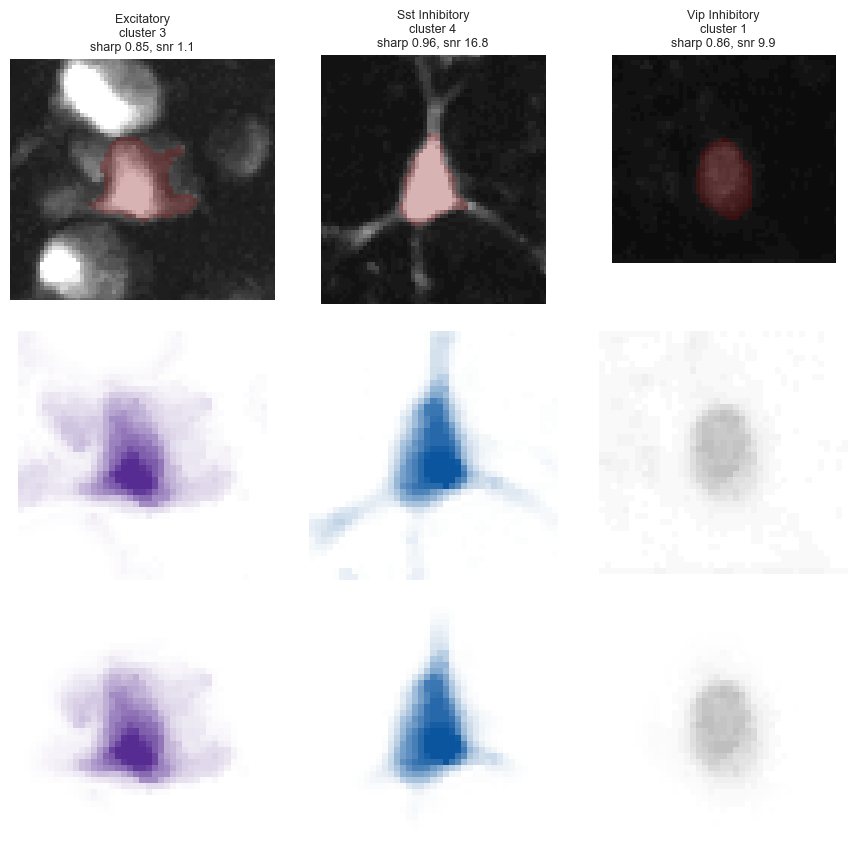

In [10]:
import visual_behavior.visualization.ophys.summary_figures as sf

HALF_WIDTH, LOW_PCT, HIGH_PCT, GAMMA, DILATION, FADE_SIGMA = 20, 50, 95, 1.0, 2, 1.5
ISOLATE_DILATION, ISOLATE_SIGMA = 4, 2   # row 3 only: how far around the target ROI to keep

# one example cell per cell type, taken from its chosen session
examples = matched_cells_table[['cell_specimen_id', 'experience_level', 'ophys_experiment_id']].merge(cluster_meta[['cluster_id', 'cell_type']], left_on='cell_specimen_id', right_index=True)
examples = examples[examples.experience_level == examples.cell_type.map(cell_tiles.SESSION_BY_CELL_TYPE)]
examples = examples.groupby('cell_type').sample(1, random_state=0)  # change random_state to see other cells

fig, ax = plt.subplots(3, len(examples), figsize=(3 * len(examples), 9))
for i, (_, row) in enumerate(examples.iterrows()):
    dataset = cell_tiles.get_sdk_cache().get_behavior_ophys_experiment(row.ophys_experiment_id)
    max_projection = np.asarray(getattr(dataset.max_projection, 'data', dataset.max_projection), dtype=float)
    cell_roi_id = dataset.cell_specimen_table.loc[row.cell_specimen_id].cell_roi_id
    sf.plot_cell_zoom(dataset.roi_masks, max_projection, cell_roi_id, spacex=HALF_WIDTH, spacey=HALF_WIDTH,
                      show_mask=True, ax=ax[0, i])
    m = cell_tiles.crispness(max_projection, cell_tiles.get_roi_mask(dataset.roi_masks, cell_roi_id))
    ax[0, i].set_title(f"{row.cell_type}\ncluster {row.cluster_id}\nsharp {m['edge_sharpness']:.2f}, snr {m['snr']:.1f}", fontsize=9)
    for r, isolate in [(1, False), (2, True)]:   # row 2: neighbor fade only; row 3: isolate target cell
        ax[r, i].imshow(cell_tiles.make_tile(max_projection, dataset.roi_masks, cell_roi_id, row.cluster_id, HALF_WIDTH,
                                             LOW_PCT, HIGH_PCT, GAMMA, DILATION, FADE_SIGMA,
                                             isolate, ISOLATE_DILATION, ISOLATE_SIGMA))
        ax[r, i].axis('off')
ax[1, 0].set_ylabel('neighbor fade'); ax[2, 0].set_ylabel('isolated')
fig.tight_layout()

## Make tiles
Loads each experiment once; slow for the full set. To test settings first, pass a subset, e.g. `cluster_meta.sample(50, random_state=0)`.

In [11]:
cluster_meta_to_plot = cluster_meta  # all clustered cells; for a quick test: cluster_meta.sample(50, random_state=2)
manifest = cell_tiles.make_all_tiles(cluster_meta_to_plot, matched_cells_table, tile_dir,
                                     half_width=20, low_pct=50, high_pct=95, gamma=1.0,
                                     dilation=2, fade_sigma=1.5,
                                     isolate=True, isolate_dilation=4, isolate_sigma=2)
manifest.groupby('cell_type')[['edge_sharpness', 'snr']].describe().T

3897 of 3901 clustered cells found in their chosen session
1/131 experiment 795076128: 117 cells


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.6.0-alpha, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


2/131 experiment 795953296: 28 cells


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.6.0-alpha, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


3/131 experiment 808619543: 109 cells


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.6.0-alpha, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


... (247 outputs left out)

behavior_ophys_experiment_1086910722.nwb: 100%|██████████| 488M/488M [00:42<00:00, 11.5MMB/s]    
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.6.0-alpha, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


131/131 experiment 1086910729: 28 cells


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.6.0-alpha, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


cell_type              Excitatory  Sst Inhibitory  Vip Inhibitory
edge_sharpness count  3284.000000      194.000000      398.000000
               mean      0.941087        0.891204        0.895071
               std       0.290146        0.091175        0.085618
               min      -4.666667        0.461538        0.500000
               25%       0.880597        0.847578        0.848359
               50%       1.000000        0.904069        0.910913
               75%       1.000000        0.948049        0.955801
               max       7.000000        1.000000        1.000000
snr            count  3284.000000      194.000000      398.000000
               mean           inf       14.735218       14.065714
               std            NaN       11.028478       11.628808
               min      -0.334951        0.342135        0.710889
               25%       0.881718        6.827656        5.777574
               50%       1.785116       11.460258       10.780322
               75%       3.514483       20.528953       18.963703
               max            inf       58.200838       82.483504

In [12]:
print(tile_dir)
manifest.filename.head()

/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/Final Figures/platform_paper_figures/cover_art/cell_tiles_isolated


0    100_Exc_cluster10_csid1086551315_expt795076128...
1    100_Exc_cluster10_csid1086550804_expt795076128...
2    100_Exc_cluster06_csid1086541251_expt795076128...
3    109_Exc_cluster03_csid1086540341_expt795076128...
4    092_Exc_cluster02_csid1086539950_expt795076128...
Name: filename, dtype: object

## Pick crisp cells
`edge_sharpness` ~1 = brightness drops to background right at the cell edge (crisp); ~0 = diffuse halo (blurry). `snr` = cell brightness over background noise. Each row shows random tiles from one quantile bin, lowest on top. Find the row where tiles start looking crisp, then set the cutoffs below.

In [13]:
print(manifest.shape, manifest.columns.tolist())
manifest.groupby('cell_type')[['edge_sharpness', 'snr']].agg(['count', 'size', 'mean'])

(3876, 8) ['cell_specimen_id', 'ophys_experiment_id', 'cluster_id', 'cluster_label', 'cell_type', 'filename', 'edge_sharpness', 'snr']


edge_sharpness                   snr                 
                        count  size      mean count  size       mean
cell_type                                                           
Excitatory               3284  3284  0.941087  3284  3284        NaN
Sst Inhibitory            194   194  0.891204   194   194  14.735218
Vip Inhibitory            398   398  0.895071   398   398  14.065714

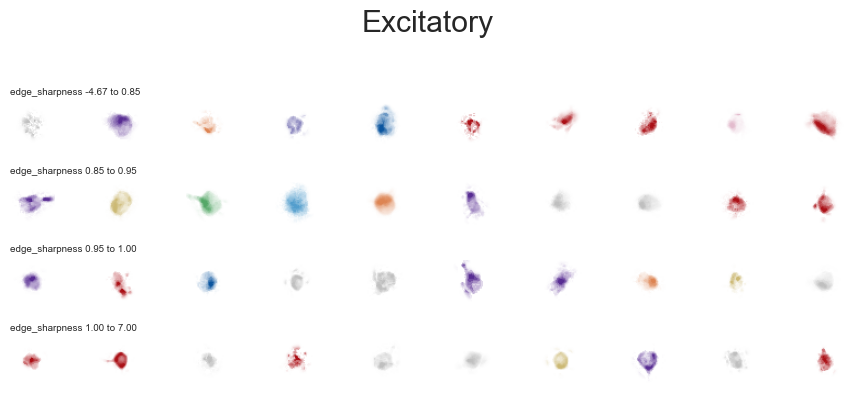

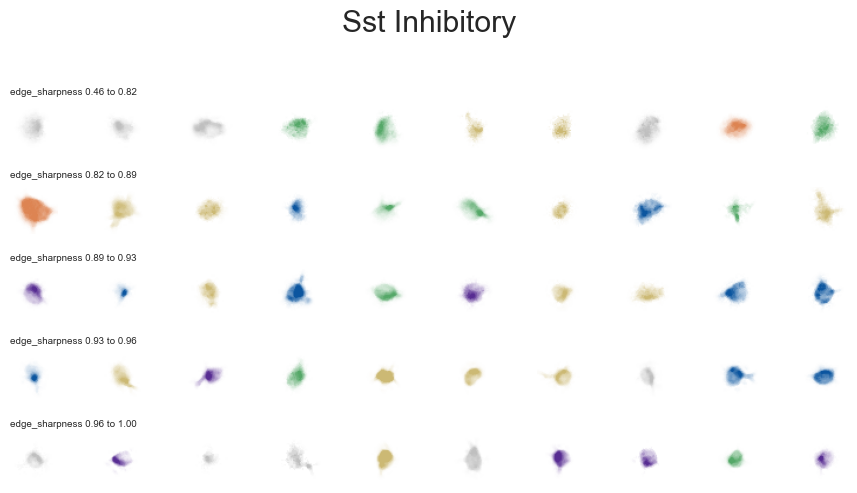

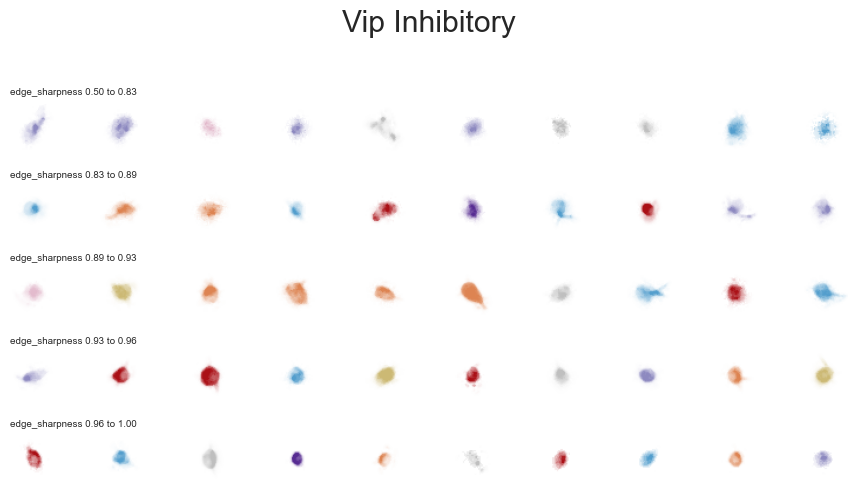

In [14]:
for cell_type in sorted(manifest.cell_type.unique()):  # only cell types present (a test subset may lack some)
    cell_tiles.preview_by_metric(manifest, tile_dir, 'edge_sharpness', cell_type=cell_type)

In [15]:
# Cutoffs chosen from the previews above; edit per cell type
SHARPNESS_CUTOFF = {'Excitatory': 0.5, 'Sst Inhibitory': 0.5, 'Vip Inhibitory': 0.5}
SNR_CUTOFF = 0

crisp = manifest[(manifest.edge_sharpness > manifest.cell_type.map(SHARPNESS_CUTOFF)) & (manifest.snr > SNR_CUTOFF)]
crisp.to_csv(os.path.join(tile_dir, 'tile_manifest_crisp.csv'), index=False)
pd.concat([manifest.groupby('cell_type').size(), crisp.groupby('cell_type').size()], axis=1, keys=['all', 'crisp'])

,all,crisp
cell_type,,
Excitatory,3284,3174
Sst Inhibitory,194,191
Vip Inhibitory,398,397


## Preview
One row per cluster, per cell type: check crop size, contrast, and neighboring cells.

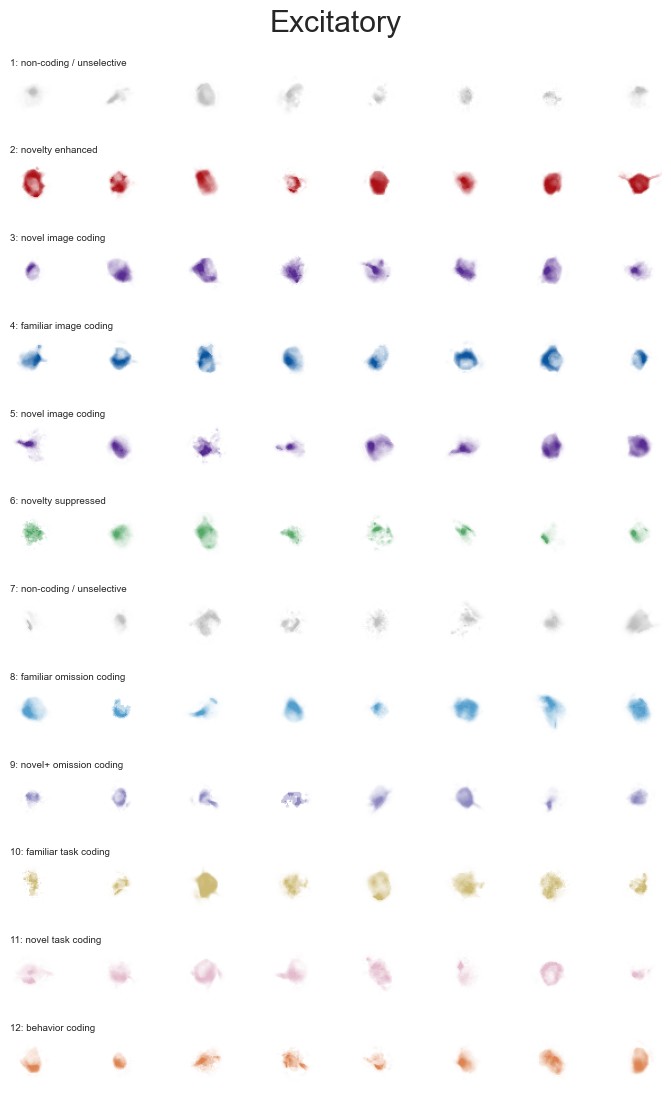

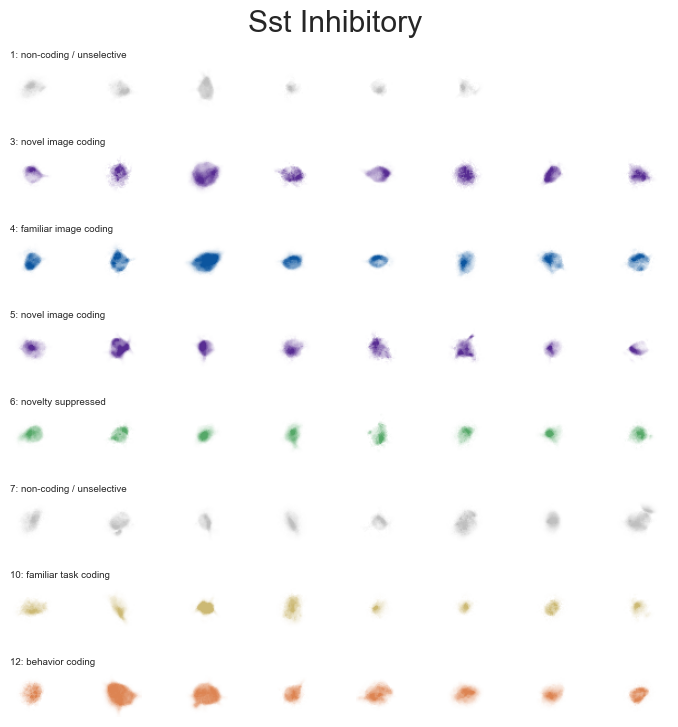

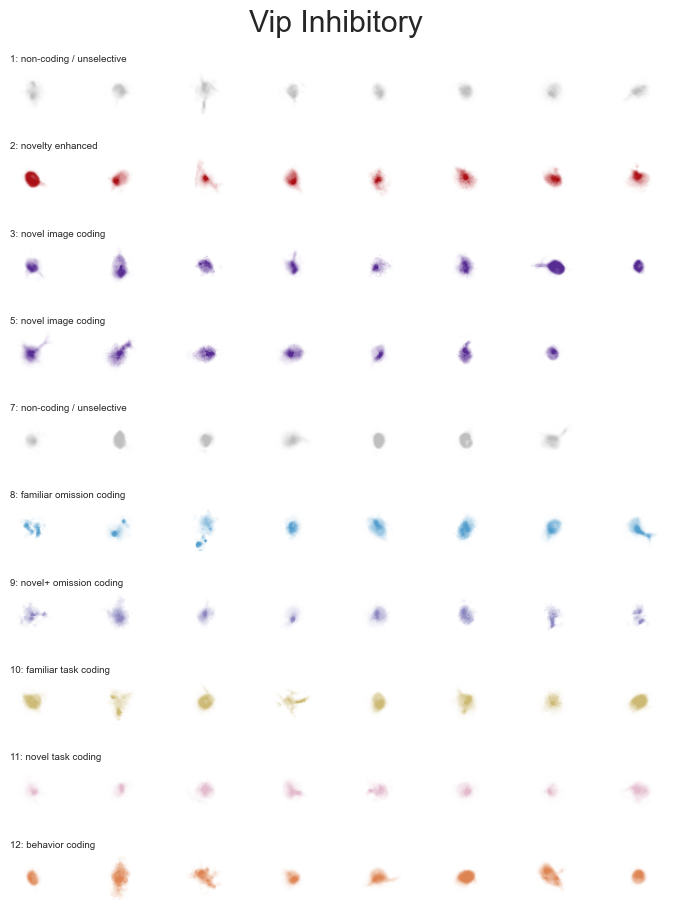

In [16]:
for cell_type in ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']:
    fig = cell_tiles.preview_tiles(crisp, tile_dir, n_per_cluster=8, cell_type=cell_type)
    fig.suptitle(cell_type, y=1.02)
    fig.savefig(os.path.join(save_dir, f'tile_preview_{cell_type.split(" ")[0]}.png'), dpi=300, bbox_inches='tight')

In [17]:
dataset.stimulus_templates

,unwarped,warped
image_name,,
im065,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[198, 197, 201, 207, 207, 202, 198, 201, 207,..."
im077,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[129, 135, 140, 142, 140, 135, 129, 124, 117,..."
im066,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[83, 85, 82, 78, 78, 81, 84, 84, 82, 82, 84, ..."
im061,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[125, 126, 126, 126, 125, 125, 125, 125, 125,..."
im063,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[105, 108, 107, 101, 97, 96, 98, 101, 103, 10..."
im062,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[103, 103, 103, 105, 112, 125, 145, 172, 204,..."
im085,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[54, 56, 50, 45, 45, 51, 56, 55, 51, 48, 49, ..."
im069,"[[nan, nan, nan, nan, nan, nan, nan, nan, nan,...","[[251, 248, 255, 255, 255, 254, 246, 248, 255,..."


## Cover design: iris
Every crisp neuron from functional clusters 2–12 becomes one point of an iris (no manual steps):
- **angle** = the cell's position around the ring of the UMAP functional map (neighbors on the eye are neighbors in functional space)
- **radius** = cell type: Vip at the pupil edge, Excitatory in the middle, Sst at the outer rim
- color = functional cluster (graphical-abstract palette); top 17% of the page kept clear for the masthead

Writes `cover_iris_light.png`, `cover_iris_dark.png` (2550 × 3300 px = 8.5 × 11 in at 300 dpi) and `cover_iris_layout.csv` (which cell is where) to `cover_art/designs/`.
Layout settings: `make_cover.IRIS`.

In [ ]:
import make_cover

design_dir = os.path.join(save_dir, 'designs')
os.makedirs(design_dir, exist_ok=True)

# UMAP coordinates + cluster / cell type for each clustered cell
umap_df = pd.read_hdf(os.path.join(data_dir, 'umap_results_df.h5'), key='df')
umap_csv = os.path.join(design_dir, 'umap_cells.csv')
umap_df[['x', 'y']].join(cluster_meta[['cluster_id', 'cell_type']]).to_csv(umap_csv)

paths = make_cover.make_cover(umap_csv, os.path.join(tile_dir, 'tile_manifest_crisp.csv'), tile_dir, design_dir)
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
for a, p in zip(ax, paths):
    a.imshow(plt.imread(p)); a.axis('off'); a.set_title(os.path.basename(p))